# DSCI 552 Midterm Exam 1

**Name:** Manvika Satish  
**GitHub Username:** manvsatish  
**USC ID:** 5582061880

## Midterm Problem #8

## (a) Data Exploration and Preprocessing

### (i) Import and Inspect the Dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#random seed
RANDOM_STATE = 552

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [2]:
# dataset path relative to the notebook dir
data_path = Path("../data/student-mat.csv")
print("Dataset exists:", data_path.exists())
print("Dataset path:", data_path)

# stop if dataset is not in expected location
assert data_path.exists(), (
    f"Dataset was not found at {data_path}"
)

# uci student-performance csv uses semicolons to separate
student_data = pd.read_csv(data_path, sep=";",)
print("Dataset shape:", student_data.shape)
display(student_data.head()) #first five observations
print("\nDataset information:")
student_data.info()
print("\nMissing values by column:")
display(student_data.isna().sum())
print("\nNumeric summary:")
display(student_data.describe().T)

Dataset exists: True
Dataset path: ../data/student-mat.csv
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-n

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


### (ii) Select and Preprocess the Required Variables

I selected the variables specified in the question, encoded `schoolsup` as 0 for `no` and 1 for `yes`, and combined weekday and weekend alcohol consumption into `alc` by taking their average. The original `Dalc` and `Walc` columns are then removed.

In [3]:
#required variables
selected_columns = ["age", "studytime", "schoolsup", "goout", "Dalc", "Walc", "health", "absences", "G3"]
preprocessed_data = student_data[selected_columns].copy()

#encode extra educational support as a binary num var
preprocessed_data["schoolsup"] = (preprocessed_data["schoolsup"].map({"no": 0, "yes": 1}))
preprocessed_data["alc"] = (preprocessed_data[["Dalc", "Walc"]].mean(axis=1)) # weekday + weekend alc consumption
preprocessed_data = preprocessed_data.drop(columns=["Dalc", "Walc"]) # remove the two original alcohol-consumption vars

# final col order
preprocessed_data = preprocessed_data[["age", "studytime", "schoolsup", "goout", "health", "absences", "alc", "G3"]]

# validate results
assert preprocessed_data["schoolsup"].isin([0, 1]).all()
assert not preprocessed_data.isna().any().any()
assert preprocessed_data.shape == (395, 8)

print("Preprocessed dataset shape:", preprocessed_data.shape,)
print("\nPreprocessed data types:")
display(preprocessed_data.dtypes.to_frame(name="Data Type"))
print("\nFirst five preprocessed rows:")
display(preprocessed_data.head())
print("\nPreprocessed summary:")
display(preprocessed_data.describe().T)

Preprocessed dataset shape: (395, 8)

Preprocessed data types:


,Data Type
age,int64
studytime,int64
schoolsup,int64
goout,int64
health,int64
absences,int64
alc,float64
G3,int64



First five preprocessed rows:


,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10



Preprocessed summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
schoolsup,395.0,0.129114,0.335751,0.0,0.0,0.0,0.0,1.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
health,395.0,3.554430,1.390303,1.0,3.0,4.0,5.0,5.0
absences,395.0,5.708861,8.003096,0.0,0.0,4.0,8.0,75.0
alc,395.0,1.886076,0.992195,1.0,1.0,1.5,2.5,5.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


### (iii) Outlier Detection Using the IQR Method

For each independent variable, I defined an outlier as an observation below $Q_1-1.5(IQR)$ or above $Q_3+1.5(IQR)$, where $IQR=Q_3-Q_1$. I reported the number of outliers and displayed boxplots for visual inspection. I didn't automatically remove these observations because the question only asked for their identification.

IQR outlier summary:


,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,age,16.0,18.0,2.0,13.00,21.00,1
1,studytime,1.0,2.0,1.0,-0.50,3.50,27
2,schoolsup,0.0,0.0,0.0,0.00,0.00,51
3,goout,2.0,4.0,2.0,-1.00,7.00,0
4,health,3.0,5.0,2.0,0.00,8.00,0
5,absences,0.0,8.0,8.0,-12.00,20.00,15
6,alc,1.0,2.5,1.5,-1.25,4.75,9


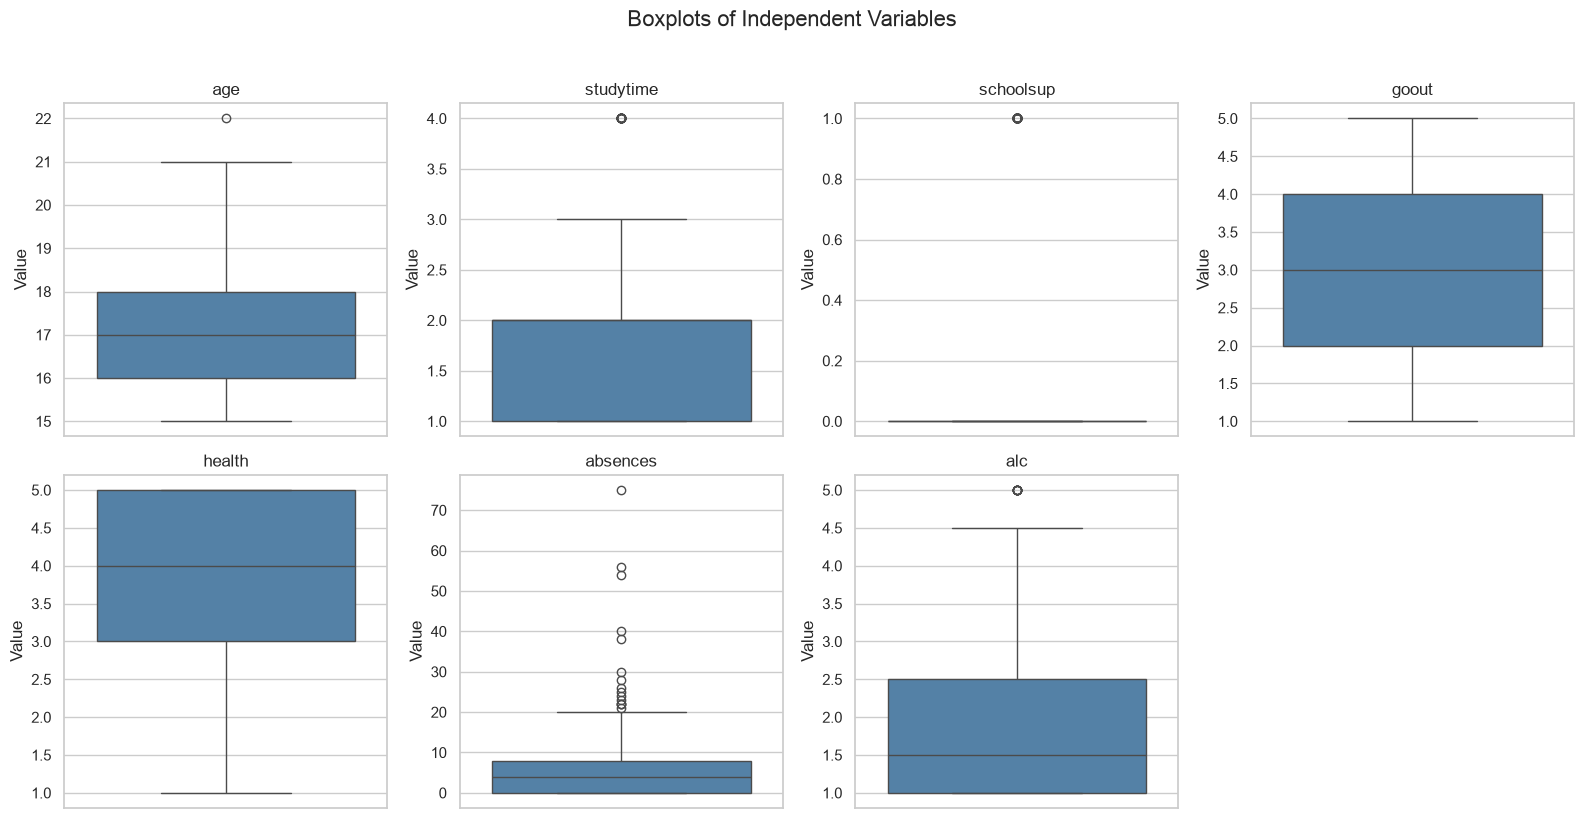

In [4]:
# sep the ind vars from the G3 target
feature_names = [column for column in preprocessed_data.columns if column != "G3"]
X = preprocessed_data[feature_names].copy()
y = preprocessed_data["G3"].copy()

# calculate iqr bounds and outlier counts for each predictor
outlier_rows = []

for feature_name in feature_names:
    first_quartile = X[feature_name].quantile(0.25)
    third_quartile = X[feature_name].quantile(0.75)
    interquartile_range = (third_quartile - first_quartile)

    lower_bound = (first_quartile - 1.5 * interquartile_range)
    upper_bound = (third_quartile + 1.5 * interquartile_range)

    outlier_mask = ((X[feature_name] < lower_bound) | (X[feature_name] > upper_bound))
    outlier_rows.append(
        {
            "Feature": feature_name,
            "Q1": first_quartile,
            "Q3": third_quartile,
            "IQR": interquartile_range,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Outlier Count": int(
                outlier_mask.sum()
            ),
        }
    )

outlier_summary = pd.DataFrame(outlier_rows)
print("IQR outlier summary:")
display(outlier_summary.round(3))

# one boxplot for every ind var
figure, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for axis, feature_name in zip(axes, feature_names):
    sns.boxplot(y=X[feature_name], ax=axis, color="steelblue")
    axis.set_title(feature_name)
    axis.set_ylabel("Value")

#hide unused 8th
for unused_axis in axes[len(feature_names):]:
    unused_axis.set_visible(False)

figure.suptitle("Boxplots of Independent Variables", fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

The IQR method identified the largest number of apparent outliers in `schoolsup`, `studytime`, and `absences`. `schoolsup` is binary, and because both its first and third quartiles are zero, its IQR is zero. As a result, all 51 valid observations with `schoolsup=1` are  labeled as outliers. These are valid category values rather than erroneous data. Similarly, `studytime` and `alc` are bounded ordinal variables, so their flagged values represent valid high response levels. The `absences` variable contains 15 observations above 20 and is strongly right-skewed, making those observations more meaningful numerical outliers. Because the question asks only to identify the outliers, I kept all observations for the subsequent analysis.

### (iv) Standardization and Principal Component Analysis

I standardized the independent variables, performed PCA, and plotted PC1 against PC2 using `G3` as the color scale. I also examined the component loadings to determine which variables contribute most to PC1 and PC2.

Standardization check:


,Mean,Standard Deviation
age,0.0,1.0
studytime,-0.0,1.0
schoolsup,0.0,1.0
goout,-0.0,1.0
health,0.0,1.0
absences,-0.0,1.0
alc,-0.0,1.0


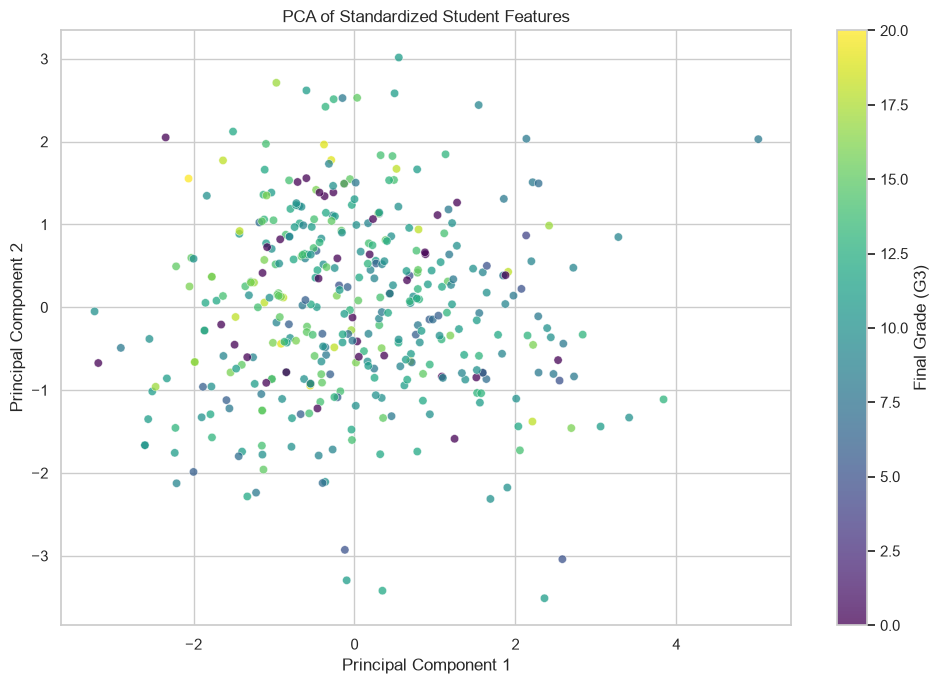

PCA component loadings:


,PC1,PC2
age,0.3819,0.5893
studytime,-0.3297,0.3857
schoolsup,-0.2482,-0.4642
goout,0.4938,-0.1396
health,0.0805,-0.4009
absences,0.2801,0.1828
alc,0.5959,-0.2737


Features contributing most to PC1:


,Absolute PC1 Loading
alc,0.5959
goout,0.4938
age,0.3819
studytime,0.3297
absences,0.2801
schoolsup,0.2482
health,0.0805


Features contributing most to PC2:


,Absolute PC2 Loading
age,0.5893
schoolsup,0.4642
health,0.4009
studytime,0.3857
alc,0.2737
absences,0.1828
goout,0.1396


Explained variance:


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.2368,0.2368
1,PC2,0.1714,0.4081
2,PC3,0.1520,0.5601
3,PC4,0.1404,0.7005
4,PC5,0.1267,0.8272
5,PC6,0.0948,0.9220
6,PC7,0.0780,1.0000


In [5]:
# standardize the ind vars
feature_scaler = StandardScaler()
X_standardized_array = feature_scaler.fit_transform(X)

X_standardized = pd.DataFrame(X_standardized_array, columns=feature_names, index=X.index) # save standardized data with the original feature names

# check that means are about 0 and std devs are about 1
standardization_summary = pd.DataFrame({"Mean": X_standardized.mean(), "Standard Deviation": X_standardized.std(ddof=0)})
print("Standardization check:")
display(standardization_summary.round(6))

# run pca on all standardized ind vars
pca = PCA()
principal_component_scores = pca.fit_transform(X_standardized)

# save pc1,pc2, and g3 for the scatterplot
pca_scores = pd.DataFrame(
    {"PC1": principal_component_scores[:, 0], "PC2": principal_component_scores[:, 1], "G3": y},
    index=X.index
)

# plot pc1 vs pc2 and color points by final grade
figure, axis = plt.subplots(figsize=(10, 7))
scatter = axis.scatter(pca_scores["PC1"], pca_scores["PC2"], c=pca_scores["G3"],cmap="viridis", alpha=0.75, edgecolor="white", linewidth=0.4)
colorbar = figure.colorbar(scatter, ax=axis)
colorbar.set_label("Final Grade (G3)")
axis.set_xlabel("Principal Component 1")
axis.set_ylabel("Principal Component 2")
axis.set_title("PCA of Standardized Student Features")
plt.tight_layout()
plt.show()

# create a table of the pc1 and pc2 loadings
pca_loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=["PC1", "PC2"])
print("PCA component loadings:")
display(pca_loadings.round(4))
pc1_contributions = pca_loadings["PC1"].abs().sort_values(ascending=False) # rank features by absolute loading size
pc2_contributions = pca_loadings["PC2"].abs().sort_values(ascending=False)
print("Features contributing most to PC1:")
display(pc1_contributions.to_frame(name="Absolute PC1 Loading").round(4))
print("Features contributing most to PC2:")
display(pc2_contributions.to_frame(name="Absolute PC2 Loading").round(4))

# show the variance explained by each principal component
explained_variance_table = pd.DataFrame(
    {
        "Principal Component": [f"PC{component_number}" for component_number in range(1, len(feature_names) + 1)],
        "Explained Variance Ratio": pca.explained_variance_ratio_,
        "Cumulative Explained Variance": np.cumsum(
            pca.explained_variance_ratio_
        )
    }
)

print("Explained variance:")
display(explained_variance_table.round(4))

#### PCA Interpretation

The standardization was successful because every independent variable has a mean close to 0 and a standard deviation of 1. PC1 explains 23.68% of the total variance. The features with the largest absolute PC1 loadings are `alc` (0.5959), `goout` (0.4938), and `age`
(0.3819). So, PC1 is primarily associated with alcohol consumption, going out, and age. Higher PC1 scores generally correspond
to higher values of these variables, while `studytime` and `schoolsup` contribute in the other direction. PC2 explains 17.14% of the total variance. The features with the largest absolute PC2 loadings are `age` (0.5893), `schoolsup` (0.4642), `health` (0.4009), and `studytime` (0.3857). Age and study time contribute in the positive direction, while school support and health contribute in the negative direction.

Together, PC1 and PC2 explain 40.81% of the total variation in the independent variables. The PCA scatterplot shows substantial overlap among the different `G3` colors, so the first two principal components do not clearly separate students according to their final grades.

## (b) Linear Regression

### (i) Train-Test Split

I split the standardized independent variables and the `G3` target into 80% training data and 20% testing data. I used random seed 552 to make the split reproducible.

In [6]:
# split the standardized data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X_standardized, y, test_size=0.20, random_state=RANDOM_STATE)

print("X training shape:", X_train.shape) # display the sizes of the train and test sets
print("X testing shape:", X_test.shape)
print("y training shape:", y_train.shape)
print("y testing shape:", y_test.shape)

# validate
assert len(X_train) + len(X_test) == len(X_standardized)
assert len(y_train) + len(y_test) == len(y)

print("\nTraining percentage:", round(len(X_train) / len(X_standardized) * 100, 2))
print("Testing percentage:", round(len(X_test) / len(X_standardized) * 100, 2))
print("Random seed:", RANDOM_STATE)

X training shape: (316, 7)
X testing shape: (79, 7)
y training shape: (316,)
y testing shape: (79,)

Training percentage: 80.0
Testing percentage: 20.0
Random seed: 552


### (ii) Build the Linear, Ridge, and Lasso Regression Models

I trained an ordinary linear regression model and two regularized linear regression models. Ridge and Lasso both use the required regularization strength of $\alpha=0.1$.

In [7]:
linear_model = LinearRegression() #three regression models
ridge_model = Ridge(alpha=0.1)
lasso_model = Lasso(alpha=0.1, max_iter=10000)

# train each model using the training set
linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)
print("All three regression models were trained successfully.")
print("Linear Regression intercept:", round(linear_model.intercept_, 4))
print("Ridge intercept:", round(ridge_model.intercept_, 4))
print("Lasso intercept:", round(lasso_model.intercept_, 4))

All three regression models were trained successfully.
Linear Regression intercept: 10.6294
Ridge intercept: 10.6294
Lasso intercept: 10.6251


### (iii) Test and Compare the Three Models

I evaluated the models on the test set using MAE, RMSE, and $R^2$. Lower MAE and RMSE values would indicate better performance, and hhigher $R^2$ values indicate better performance.

In [8]:
models = {"Linear Regression": linear_model, "Ridge Regression": ridge_model, "Lasso Regression": lasso_model}

#predictions and teste metrics
model_predictions = {}
evaluation_rows = []
for model_name, model in models.items():
    predictions = model.predict(X_test)
    model_predictions[model_name] = predictions
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r_squared = r2_score(y_test, predictions)

    evaluation_rows.append({"Model": model_name, "MAE": mae, "RMSE": rmse, "R-squared": r_squared})

# model comp table
evaluation_results = pd.DataFrame(evaluation_rows)
print("Test-set model performance:")
display(evaluation_results.round(4))

#best model for each metric
best_mae_model = evaluation_results.loc[evaluation_results["MAE"].idxmin(), "Model"]
best_rmse_model = evaluation_results.loc[evaluation_results["RMSE"].idxmin(), "Model"]
best_r_squared_model = evaluation_results.loc[evaluation_results["R-squared"].idxmax(), "Model"]
print("Best model by MAE:", best_mae_model)
print("Best model by RMSE:", best_rmse_model)
print("Best model by R-squared:", best_r_squared_model)

Test-set model performance:


,Model,MAE,RMSE,R-squared
0,Linear Regression,3.4180,4.7558,0.0282
1,Ridge Regression,3.4181,4.7559,0.0282
2,Lasso Regression,3.4471,4.7938,0.0126


Best model by MAE: Linear Regression
Best model by RMSE: Linear Regression
Best model by R-squared: Linear Regression


#### Model Comparison

Linear Regression seemed to perform best according to all three test metrics. It produced the lowest MAE of 3.4180, the lowest RMSE of 4.7558, and the highest $R^2$ of 0.0282. Ridge Regression got nearly identical results, while Lasso Regression performed slightly worse. An MAE of 3.4180 means that the Linear Regression predictions are different from the actual final grades by approximately 3.42 grade points on average. Its RMSE of 4.7558 is higher than its MAE, indicating that some of the predictions have relatively larger errors.

The Linear Regression $R^2$ of 0.0282 means that the model explains only about 2.82% of the variation in final grades in the test set. So, although Linear Regression is the best of the three models, all three models have weak predictive performance with the selected features.

### (iv) Interpretation of the R-squared Values

The Linear Regression and Ridge Regression models both have an $R^2$ of approximately 0.0282. This means that each model explains only about 2.82% of the variation in students' final grades in the test set. The Lasso Regression model has an $R^2$ of 0.0126, which means that it explains approximately 1.26% of the variation in final grades. All three $R^2$ values are close to zero, which shows that the selected independent variables have a limited linear predictive power for `G3`. Linear and Ridge perform almost identically, while Lasso loses a small amount of explanatory power because its coefficient shrinkage is stronger. These results show me that important predictors of final grades are not included in the selected feature set or that some relationships may not be represented well enough by a simple linear model.

### (v) Model Coefficients and Intercepts

The table below compares the coefficients and intercepts from all three models. Because the independent variables were standardized, each coefficient represents the expected change in `G3` that is associated with a one-standard-deviation increase in that variable, while holding the other variables constant.

In [9]:
#one table containing every coefficient
coefficient_table = pd.DataFrame({"Feature": feature_names, "Linear Regression": linear_model.coef_, "Ridge Regression": ridge_model.coef_, "Lasso Regression": lasso_model.coef_})
intercept_row = pd.DataFrame({"Feature": ["Intercept"], "Linear Regression": [linear_model.intercept_], "Ridge Regression": [ridge_model.intercept_], "Lasso Regression": [lasso_model.intercept_]})

#combine intercepts and coefficients into one table
coefficient_table = pd.concat([intercept_row, coefficient_table], ignore_index=True)
print("Model coefficients and intercepts:")
display(coefficient_table.round(4))

Model coefficients and intercepts:


,Feature,Linear Regression,Ridge Regression,Lasso Regression
0,Intercept,10.6294,10.6294,10.6251
1,age,-0.7811,-0.7807,-0.6304
2,studytime,0.4448,0.4447,0.3491
3,schoolsup,-0.6825,-0.6822,-0.5475
4,goout,-0.5825,-0.5823,-0.4856
5,health,-0.2433,-0.2432,-0.1416
6,absences,0.1928,0.1927,0.0720
7,alc,0.0371,0.0369,-0.0000


### (vi) Relationships Between the Independent Variables and G3

Because the independent variables were standardized, the coefficient magnitudes can be compared directly. A positive coefficient shows that `G3` tends to increase as the predictor increases, while a negative coefficient indicates that `G3` tends to decrease, keeping all the other
variables constant.

- **Age:** Age has a negative relationship with `G3`. In the Linear Regression model, a one-standard-deviation increase in age is associated with an ~ 0.7811-point decrease in final grade.
- **Study time:** Study time has a positive relationship with `G3`. A one-standard-deviation increase in study time is associated with an ~ 0.4448-point increase in final grade.
- **School support:** School support has a negative coefficient, which means that students receiving additional school support tend to have lower predicted final grades after controlling for the other variables. This shouldn't be interpreted as school support causing lower grades, because support may be given more to students who are already struggling.
- **Going out:** Going out has a negative relationship with `G3`. A one-standard-deviation increase in `goout` is associated with an estimated 0.5825-point decrease in final grade.
- **Health:** Health has a small negative relationship with `G3`, with a Linear Regression coefficient of -0.2433.
- **Absences:** Absences have a small positive coefficient of 0.1928. This result is somewhat unexpected and could reflect sampling variation, outliers, variables that have been left out, or relationships that are not represented well enough by a simple linear model.
- **Alcohol consumption:** Alcohol consumption has an extremely small Linear Regression coefficient of 0.0371 and is reduced to zero by Lasso. Therefore, it gives us almost no unique linear predictive value for `G3` after controlling for the other variables.

These coefficients describe associations within this dataset and should not be interpreted as causal effects.

### (vii) Differences Between the Regularization Methods

Ridge Regression uses L2 regularization, which adds a penalty based on the squared values of the coefficients. It shrinks coefficients toward zero but usually doesn't set them exactly equal to zero. In this analysis, the Ridge coefficients and test metrics are almost identical to those of ordinary Linear Regression because the selected regularization strength of 0.1 is relatively small. Lasso Regression uses L1 regularization, which adds a penalty based on the absolute values of the coefficients. It can shrink some coefficients completely to zero and therefore can also perform feature selection. In this analysis, Lasso reduced the `alc` coefficient to zero and shrank all the other coefficients more strongly. Linear Regression produced the best test results, while Ridge performed almost identically and Lasso performed slightly worse. This shows that regularization does not improve predictive performance for the current feature set. The low test $R^2$ values also show that these features explain very little about the variation in `G3`. Additional important predictors, nonlinear relationships, interaction effects, or other modeling methods may be needed to improve performance.

### (viii) Effect of Increasing the Regularization Strength

Increasing $\alpha$ would increase the penalty placed on the model coefficients. In Ridge Regression, the coefficients would be pushed closer to zero but would generally remain nonzero. In Lasso Regression, the coefficients would be pushed closer to zero, and more of them could become exactly zero. A slight increase in $\alpha$ could improve test performance if it reduces overfitting. However, if $\alpha$ becomes too large, the models would become overly simple and underfit the data. In that situation, MAE and RMSE would generally increase while $R^2$ would generally decrease.

Therefore, the effect on the test metrics isn't really guaranteed to be immediately positive or negative. The best value of $\alpha$ should be selected using cross-validation to balance model complexity and predictive performance.

### (ix) Suggested Feature Engineering Methods

Several feature engineering methods could potentially improve model performance:
1. **Include prior grades:** Add `G1` and `G2`, because students' earlier grades are likely to be strong predictors of their final grade `G3`. 
2. **Include additional student information:** Variables like past failures, parental education, weekly study time, travel time, family support, internet access, and plans for higher education may provide useful predictive information.
3. **Encode categorical variables:** One-hot encode variables like school, sex, address, family size, parental jobs, and reason for choosing the school.
4. **Transform absences:** Since `absences` is strongly right-skewed and contains several outliers, a transformation like `log1p(absences)` could reduce the influence of extreme values.
5. **Create interaction features:** Interactions such as study time with school support, study time with going out, or alcohol consumption with going out may capture relationships that are not represented by individual linear terms.
6. **Add polynomial features:** Squared terms for variables like age, study time, absences, and alcohol consumption could represent nonlinear relationships with final grades.
7. **Reconsider the alcohol feature:** Keeping `Dalc` and `Walc` separate could preserve information that may have been lost by averaging them into one `alc` variable.

These methods should be evaluated using cross-validation so that only changes that improve performance on unseen data are retained.

## Residual Analysis

I examined the residuals from all three models using residual-versus-predicted plots and normal Q-Q plots. Residuals should ideally be
randomly distributed around zero, without a clear pattern. Points that closely follow the Q-Q reference line indicate approximately normal residuals.

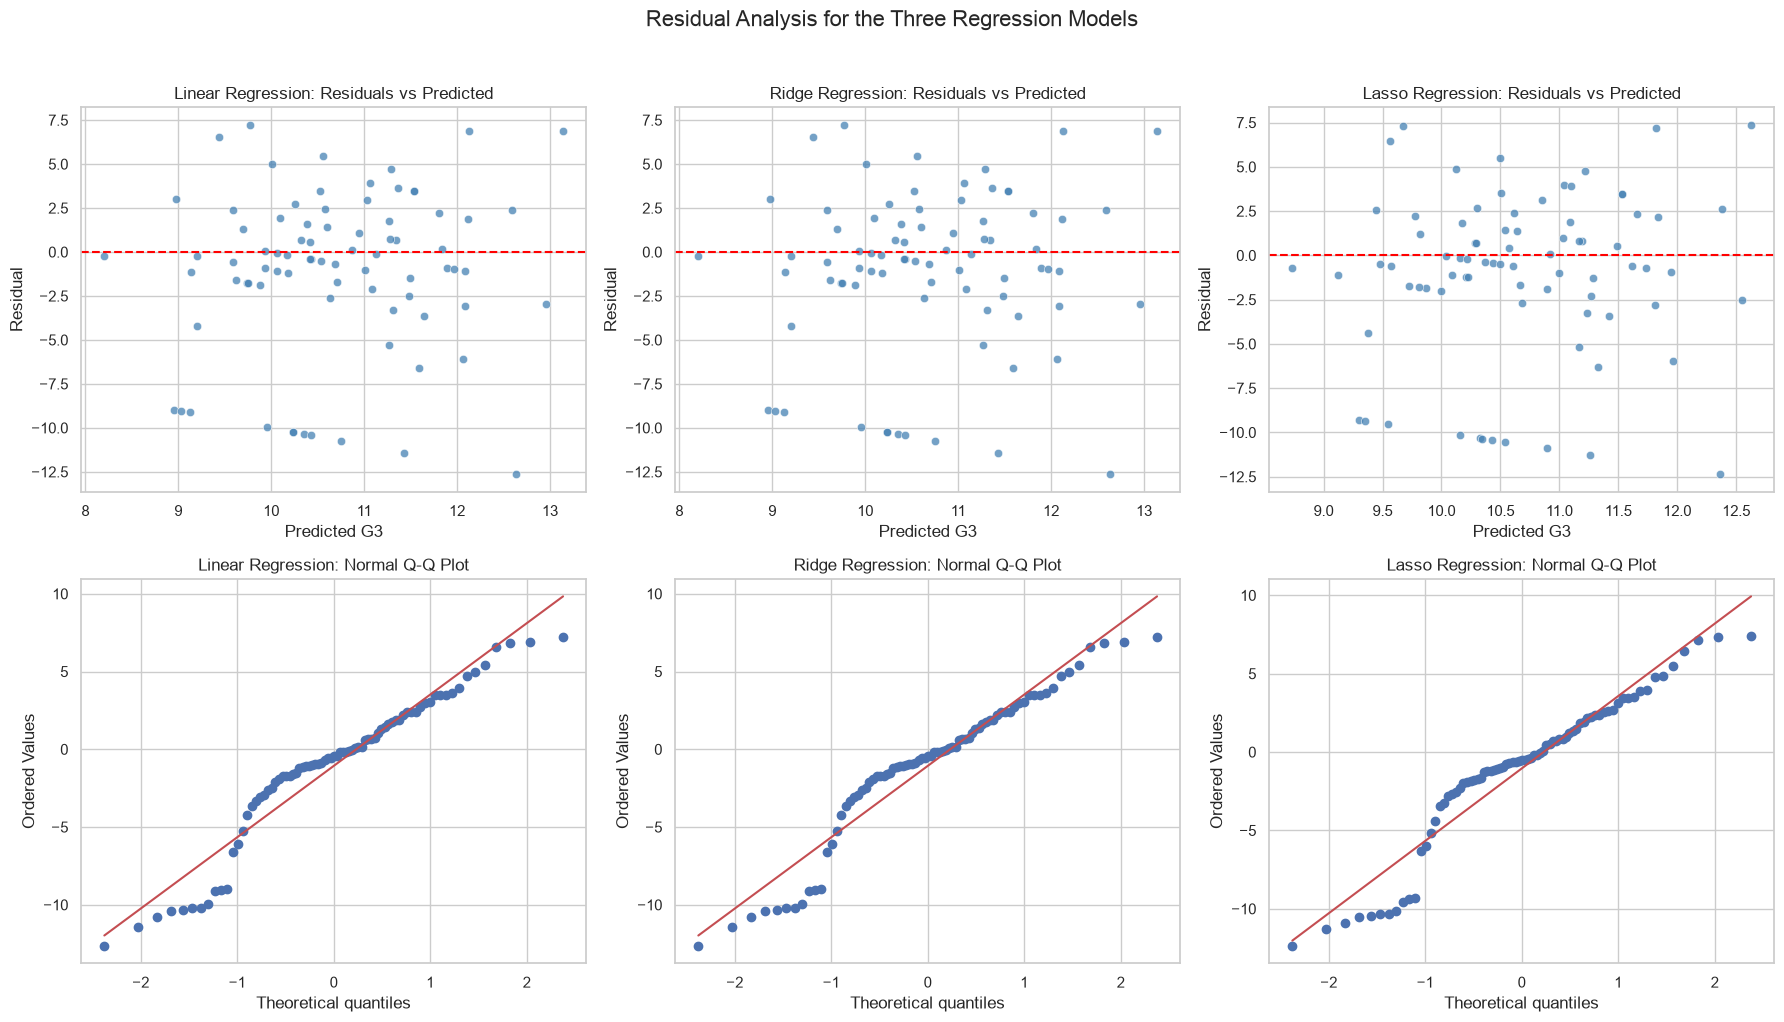

In [10]:
figure, axes = plt.subplots(2, 3, figsize=(18, 10))
for column_index, (model_name, predictions) in enumerate(model_predictions.items()):
    residuals = y_test - predictions

    # residuals vs predicted values
    sns.scatterplot(x=predictions, y=residuals, ax=axes[0, column_index], color="steelblue", alpha=0.75)
    axes[0, column_index].axhline(y=0, color="red", linestyle="--")
    axes[0, column_index].set_title(f"{model_name}: Residuals vs Predicted")
    axes[0, column_index].set_xlabel("Predicted G3")
    axes[0, column_index].set_ylabel("Residual")

    # normal qq plot of the residuals
    stats.probplot(residuals, dist="norm", plot=axes[1, column_index])
    axes[1, column_index].set_title(f"{model_name}: Normal Q-Q Plot")

figure.suptitle("Residual Analysis for the Three Regression Models", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Residual Interpretation

The three models produce very similar residual patterns, which is consistent with their similar test metrics and coefficients. Many
residuals are located around zero, but there are also several large negative residuals between approximately -9 and -13. These happen when the models overpredict by a lot for some students' final grades. The residual-versus-predicted plots don't show a fully random, constant-width cloud around zero. The models predict within a relatively narrow range, while the residuals remain widely dispersed. This suggests that the selected variables don't capture much of the variation in `G3`. Some of the visible grouping is also expected because `G3` is a discrete integer-valued grade. The Q-Q plots follow the reference line near the center but move from it a lot in the tails, especially in the lower tail. Therefore, the residuals aren't normally distributed and contain several unusually large errors. Overall, the residual analysis supports the earlier conclusion that al three models have weak predictive performance. Linear Regression and Ridge output nearly identical residuals, while Lasso doesn't provide a meaningful improvement.

## Conclusion

Among the three models, ordinary Linear Regression got the best test performance, with an MAE of 3.4180, an RMSE of 4.7558, and an $R^2$ of 0.0282. Ridge Regression produced almost identical results, while Lasso Regression performed slightly worse and reduced the coefficient for alcohol consumption to zero. Despite Linear Regression being the best model, all three models explained very little of the variation in final grades. The residual analysis also revealed several large prediction errors and departures from normality. Therefore, the selected independent variables alone aren't enough to accurately predict `G3`. Adding stronger predictors—particularly earlier grades such as `G1` and `G2`—and considering nonlinear or interaction features could improve performance by a lot.